<a href="https://colab.research.google.com/github/rachakondasaivarshini/GAN-PROGRAMS/blob/main/GAN_EXP11_POSTLAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

100%|██████████| 26.4M/26.4M [00:01<00:00, 18.6MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 302kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.50MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 11.8MB/s]


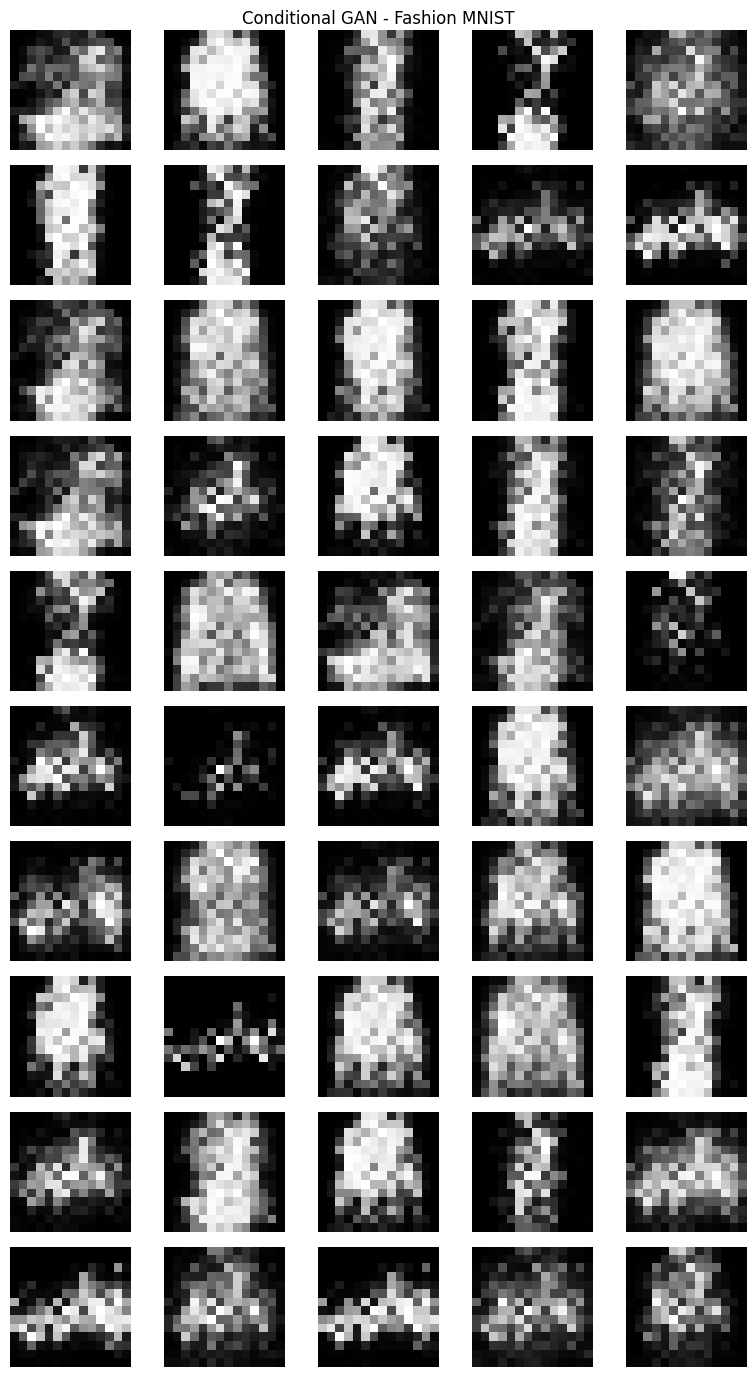

In [1]:

import torch
from torch import nn
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"

transform = transforms.Compose([
    transforms.Resize((14, 14)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

data = datasets.FashionMNIST(
    "/content/data",
    download=True,
    transform=transform
)

loader = torch.utils.data.DataLoader(
    data, batch_size=64, shuffle=True
)

# Generator
G = nn.Sequential(
    nn.Linear(42, 128),
    nn.ReLU(),
    nn.Linear(128, 196),
    nn.Tanh()
).to(device)

# Discriminator
D = nn.Sequential(
    nn.Linear(206, 128),
    nn.LeakyReLU(0.2),
    nn.Linear(128, 1)
).to(device)

og = torch.optim.Adam(G.parameters(), lr=0.0002)
od = torch.optim.Adam(D.parameters(), lr=0.0002)

# Training
for epoch in range(5):
    for x, labels in loader:
        x = x.to(device).flatten(1)
        labels = labels.to(device)

        n = len(x)

        y = nn.functional.one_hot(
            labels, 10
        ).float()

        z = torch.randn(n, 32, device=device)

        fake = G(torch.cat([z, y], 1))

        real_score = D(torch.cat([x, y], 1))
        fake_score = D(torch.cat([fake.detach(), y], 1))

        loss_d = (
            nn.functional.softplus(-real_score).mean()
            + nn.functional.softplus(fake_score).mean()
        )

        od.zero_grad()
        loss_d.backward()
        od.step()

        fake = G(torch.cat([z, y], 1))
        score = D(torch.cat([fake, y], 1))

        loss_g = nn.functional.softplus(-score).mean()

        og.zero_grad()
        loss_g.backward()
        og.step()

# Generate grid: 10 classes, 5 variations
G.eval()

with torch.no_grad():
    z = torch.randn(10, 5, 32, device=device)

    labels = torch.arange(10, device=device)
    labels = labels.repeat_interleave(5)

    y = nn.functional.one_hot(labels, 10).float()

    z = z.reshape(50, 32)

    images = G(torch.cat([z, y], 1))
    images = images.cpu().reshape(10, 5, 14, 14)

fig, axes = plt.subplots(10, 5, figsize=(8, 14))

for i in range(10):
    for j in range(5):
        axes[i, j].imshow(
            (images[i, j] + 1) / 2,
            cmap="gray"
        )
        axes[i, j].axis("off")

    axes[i, 0].set_ylabel(
        str(i), rotation=0, labelpad=15
    )

plt.suptitle("Conditional GAN - Fashion MNIST")
plt.tight_layout()
plt.show()
